Задание 1. Построить параметрически заданную кривую. Добавить линии
сетки, подписи осей и заголовок графика, в котором вывести название кривой. Для
построения графиков использовать модуль matplotlib.pyplot.
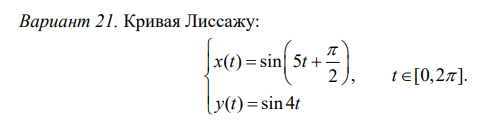

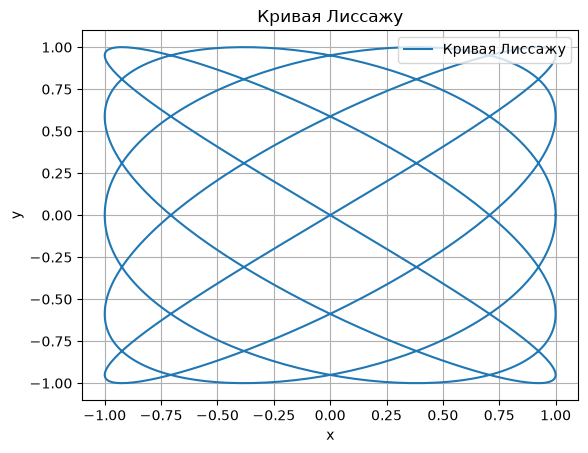

In [17]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 2 * np.pi, 1000)
x = np.sin(5 * t + np.pi / 2)
y = np.sin(4 * t)

plt.plot(x, y, label = r"Кривая Лиссажу")
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Кривая Лиссажу")
plt.legend(loc='upper right')
plt.show()

Задание 2. Построить графики функций y(x), z(x) на одних и тех же осях
координат, используя различные типы и цвета линий, маркеров. Добавить легенду.
, , , P T H L
n n n n
– многочлены Лежандра, Чебышева, Эрмита и Лагерра
соответственно, для работы с ними использовать модуль numpy.polynomial.
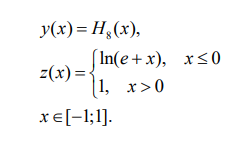

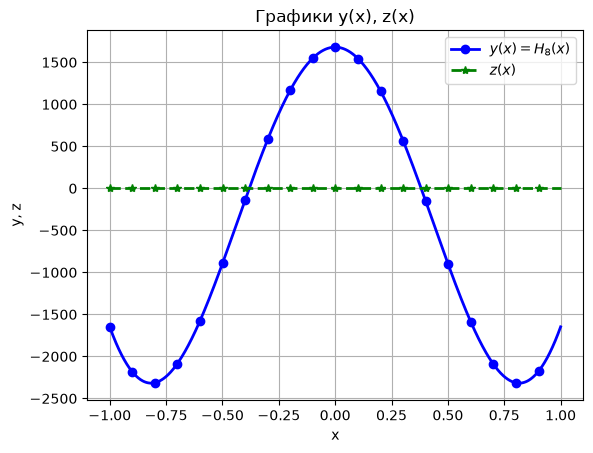

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Hermite

x = np.linspace(-1, 1, 1000)
p = Hermite([0, 0, 0, 0, 0, 0, 0, 0, 1])
y = p(x)
z = np.piecewise(x, [x <= 0, x > 0], [lambda x: np.log(np.e + x), lambda x: 1])

plt.plot(x, y, label = r'$y(x) = H_8(x)$', color = 'blue', linestyle = '-', linewidth = 2, marker = 'o', markevery = 50)
plt.plot(x, z, label = r'$z(x)$', color = 'green', linestyle = '--', linewidth = 2, marker = '*', markevery = 50)

plt.title("Графики y(x), z(x)")
plt.grid(True)
plt.xlabel('x')
plt.ylabel('y, z')
plt.legend(loc='upper right')
plt.show()

Задание 3. Написать функцию, принимающую в качестве аргумента число N
(размерность квадратной матрицы А) и с помощью модуля scipy.sparse
формирующую разреженную матрицу А из задания 1 лабораторной 2. Матрица
должна создаваться сразу в разреженном формате, без создания промежуточной
плотной матрицы. Затем с помощью функций из модуля scipy.sparse.linalg
выполнить для разреженной матрицы А задание 2 из лабораторной 2.

In [7]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spl

def createMatrix(N):
    data = []
    rows = []
    cols = []

    diagonal_values = np.arange(N - 2, N - 2 - N, -1)
    rows.extend(range(N))
    cols.extend(range(N))
    data.extend(diagonal_values)

    down_diagonal_values = N //2 - 1

    numbers_elements = N - down_diagonal_values
    rows.extend(range(down_diagonal_values, N))
    cols.extend(range(0, numbers_elements))
    data.extend([N - 2] * numbers_elements)
    first_col_values = ((N - 2) * (-1)**np.arange(N))

    skip_rows = {0}
    if 0 < down_diagonal_values < N:
        skip_rows.add(down_diagonal_values)

    for i in range(N):
        if i not in skip_rows:
            rows.append(i)
            cols.append(0)
            data.append(first_col_values[i])
    
    A = sp.csr_matrix((data, (rows, cols)), shape = (N, N))
    #print(A)
    return A

def octNormFoo(A):
    result = spl.norm(A, ord = 1)
    return result

def eigValVecFoo(A, N):
    eig_values, eig_vectors = spl.eigs(A, k = N - 2)
    return eig_values, eig_vectors

def printAbsMinOctNorm(A, eig_values, eig_vectors):
    min_abs_eig_value_idx = np.argmin(np.abs(eig_values))
    #min_abs_eig_value = eig_values[mib_abs_eig_value_idx]
    res_vector = eig_vectors[:, min_abs_eig_value_idx]
    result = np.linalg.norm(res_vector, ord = 1)
    return result
    
N = 7
A = createMatrix(N)
oct_norm = octNormFoo(A)
eig_values, eig_vectors = eigValVecFoo(A, N)
min_oct_norm = printAbsMinOctNorm(A, eig_values, eig_vectors)

print(A.toarray(), '\n')
print(oct_norm, '\n')
print(eig_values, '\n')
print(eig_vectors, '\n')
print(min_oct_norm)

[[ 5  0  0  0  0  0  0]
 [-5  4  0  0  0  0  0]
 [ 5  0  3  0  0  0  0]
 [-5  5  0  2  0  0  0]
 [ 5  0  5  0  1  0  0]
 [-5  0  0  5  0  0  0]
 [ 5  0  0  0  5  0 -1]] 

35.0 

[ 5.+0.j  4.+0.j -1.+0.j  3.+0.j  2.+0.j] 

[[-5.84751769e-02+0.j  6.45317133e-16+0.j  1.80411242e-16+0.j
   6.10622664e-16+0.j  1.80411242e-16+0.j]
 [ 2.92375885e-01+0.j -2.42424242e-01+0.j  1.52655666e-16+0.j
   3.00454106e-15+0.j -4.99600361e-16+0.j]
 [-1.46187942e-01+0.j  2.80331314e-15+0.j  2.22044605e-16+0.j
  -2.42424242e-01+0.j  4.85722573e-17+0.j]
 [ 5.84751769e-01+0.j -6.06060606e-01+0.j  1.94289029e-16+0.j
   1.08871245e-14+0.j  3.71390676e-01+0.j]
 [-2.55828899e-01+0.j  5.63438185e-15+0.j  9.43689571e-16+0.j
  -6.06060606e-01+0.j  2.49800181e-16+0.j]
 [ 6.43226946e-01+0.j -7.57575758e-01+0.j -9.15933995e-16+0.j
   1.65631397e-14+0.j  9.28476691e-01+0.j]
 [-2.61920063e-01+0.j  6.55031585e-15+0.j  1.00000000e+00+0.j
  -7.57575758e-01+0.j  1.81873734e-16+0.j]] 

1.0000000000000027


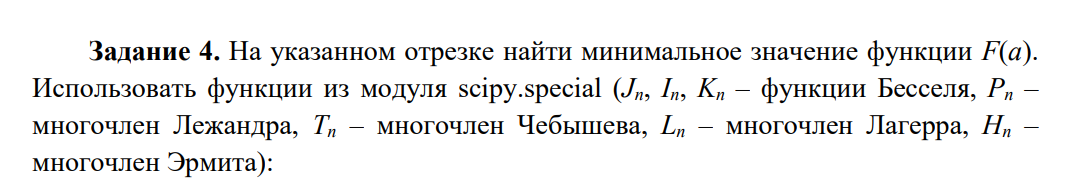
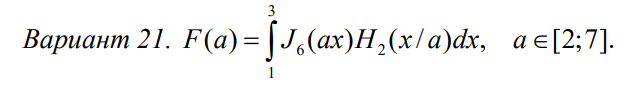

In [9]:
import numpy as np
from scipy.special import jv, eval_hermite
from scipy.optimize import minimize_scalar
from scipy.integrate import quad

def integralFoo(x, a):
    return jv(6, a * x) * eval_hermite(2, x / a)

def integral(a):
    result = quad(integralFoo, 1, 3, args=(a,))
    return result[0]

finding_min = minimize_scalar(integral, bounds = (2, 7), method = 'bounded')
print(finding_min)

 message: Solution found.
 success: True
  status: 0
     fun: -0.37953216218564056
       x: 4.029611675535487
     nit: 13
    nfev: 13


Задание 5. Для указанной в варианте функции найти точку локального
минимума. Если локальных минимумов несколько, достаточно найти только один
из них. Построить график минимизируемой функции в виде поверхности таким
образом, чтобы был виден искомый локальный минимум. Построить аналогичный
контурный график (contour).
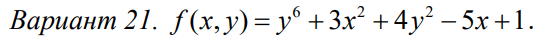

0.83333332350578 4.229371642445859e-09 

-1.083333333333333


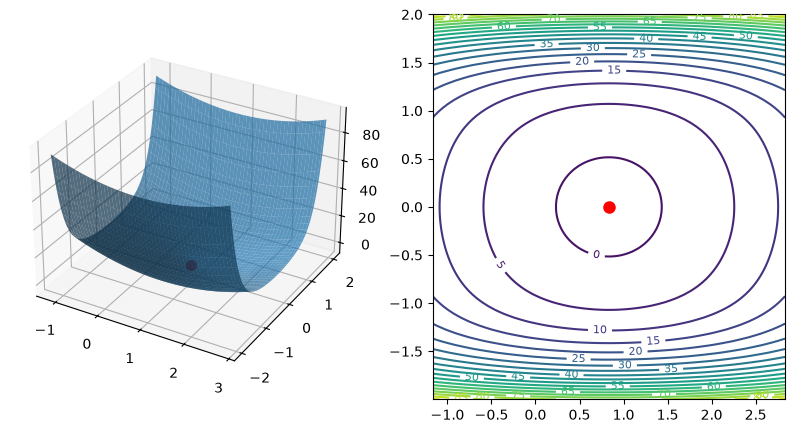

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

def foo(xy):
    x, y = xy
    return y ** 6 + 3 * x ** 2 + 4 * y ** 2 - 5 * x + 1

xy = [0, 0]
result = minimize(foo, xy)
x_min, y_min = result.x
func_min = result.fun
print(x_min, y_min, '\n')
print(func_min)

x = np.linspace(x_min - 2, x_min + 2, 100)
y = np.linspace(y_min - 2, y_min + 2, 100)
X, Y = np.meshgrid(x, y)
Z = Y ** 6 + 3 * X ** 2 + 4 * Y ** 2 - 5 * X + 1

fig = plt.figure(figsize = (10, 5))
ax_3d = fig.add_subplot(121, projection = '3d')
surf = ax_3d.plot_surface(X, Y, Z, alpha=0.7)
ax_3d.scatter(x_min, y_min, func_min, color = 'red',  s = 50, label = "min")

ax_contour = fig.add_subplot(122)
contour = ax_contour.contour(X, Y, Z, levels=20)
ax_contour.clabel(contour, inline=True, fontsize=8)
ax_contour.plot(x_min, y_min, 'ro', markersize=8)
plt.show()